# Contour comparisons — 2026-10-02

The adiabatic section uses saved data. The isothermal section now includes a
**local analytical calculation cell**, followed by solver-free visualization cells.
Rerun only a visualization cell when tuning the plot; no numerical BVP is rerun.
PNG/PDF exports go to `local_analysis_results/26-10-02/`.

## 1. Adiabatic: numerical, semi-analytical, and full analytical

The new analytical methods use $\xi=-0.85$ and $T(0^+)=0.1$ MeV.
Solid curves retain the saved full-numerical reference. Its legacy metadata
contains the old analytical comparison parameter; the numerical solution itself
is not recomputed or relabeled as a new analytical result.
Shading is the geometric band between numerical and full-analytical curves,
not a statistical uncertainty. Missing method samples remain masked.
The local recovery overlay preserves all original successes. Bands now include
2000 m/s, but only over common computed angular coverage: the full-analytical
2000 m/s branch is not bracketed inside the shared domain on the cold/intermediate
rays. No band is extrapolated beyond its available full-analytical contour.


In [6]:
from pathlib import Path
from collections import Counter
import hashlib
import importlib.util
import json
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / 'new_paper_calculations').is_dir():
    raise RuntimeError('Open this notebook with NSM_related as its working directory')
OUTPUT_DIRECTORY = ROOT / 'local_analysis_results/26-10-02'
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
ADIABATIC_PATH = ROOT / 'new_paper_calculations/26-10-02/adiabatic_xi_minus0p85/T0plus0p1-analytical-xi-minus0p85.npy'
comparison = np.load(ADIABATIC_PATH, allow_pickle=True).item()
assert comparison['production_run'] and comparison['run_complete']
assert comparison['xi'] == -0.85 and comparison['T_0plus_MeV'] == 0.1
theta_axis = np.asarray(comparison['theta_rad_axis'])
assert theta_axis[0] == 0 and theta_axis[-1] == np.pi / 2
source_hashes = {str(ADIABATIC_PATH.relative_to(ROOT)): hashlib.sha256(ADIABATIC_PATH.read_bytes()).hexdigest()}
LOCAL_REPAIR_PATH = OUTPUT_DIRECTORY / 'analytical-local-repair.npy'
repair_spec = importlib.util.spec_from_file_location('saved_local_repair', ROOT / 'new_paper_calculations/26-10-02/repair_analytical_local.py')
repair_tools = importlib.util.module_from_spec(repair_spec)
repair_spec.loader.exec_module(repair_tools)
local_repair = {}
if LOCAL_REPAIR_PATH.exists():
    local_repair = np.load(LOCAL_REPAIR_PATH, allow_pickle=True).item()
    assert local_repair['xi'] == -0.85
    for relative, digest in local_repair['source_hashes'].items():
        assert hashlib.sha256((ROOT / relative).read_bytes()).hexdigest() == digest, relative
    comparison = repair_tools.merge_adiabatic(comparison, local_repair)
    source_hashes[str(LOCAL_REPAIR_PATH.relative_to(ROOT))] = hashlib.sha256(LOCAL_REPAIR_PATH.read_bytes()).hexdigest()
    print('Loaded local analytical recovery overlay; original cluster files are unchanged.')
for method in ('analytic', 'semi_analytic'):
    success = sum(bool(row[method]['success']) for row in comparison['records'].values())
    print(f'{method}: {success}/{len(comparison["records"])} accepted evaluations; xi={comparison["xi"]}')
print('Regular plotting grid:', comparison['plot_grid']['nB_0minus_over_n0'].shape)
print('Numerical reference:', comparison['numerical_reference_grid']['role'])


Loaded local analytical recovery overlay; original cluster files are unchanged.
analytic: 749/749 accepted evaluations; xi=-0.85
semi_analytic: 704/749 accepted evaluations; xi=-0.85
Regular plotting grid: (30, 21)
Numerical reference: source_reference_only


Saved local_analysis_results/26-10-02/adiabatic-xi-minus0p85-bands-to-2000.png
Saved local_analysis_results/26-10-02/adiabatic-xi-minus0p85-bands-to-2000.pdf


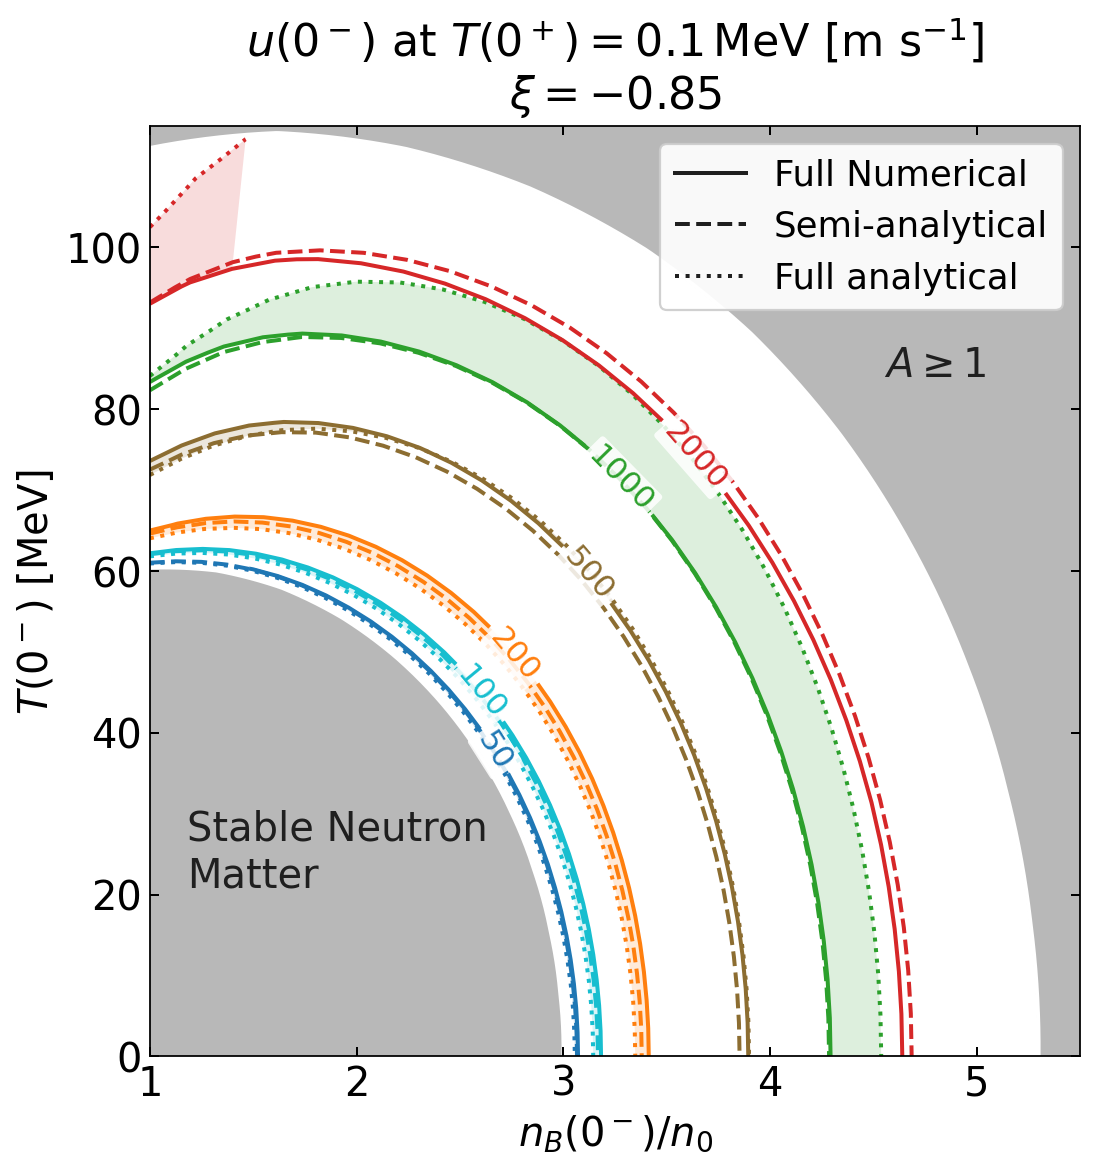

Full analytical: 749/749 accepted points
Semi-analytical: 704/749 accepted points
Semi-analytical 5000 m/s brackets: 30/30
Numerical-to-full-analytical bands, xi=-0.85, through 2000 m/s; bands stop at common computed coverage.


In [3]:
# Tunable plotting parameters
T0PLUS_MEV = 0.1
VELOCITY_CONTOUR_LEVELS_M_S = (50.0, 100.0, 200.0, 500.0, 1000.0, 2000.0, 5000.0)
VELOCITY_CONTOUR_COLORS = ("#1f77b4", "#17becf", "#ff7f0e", "#8c6d31", "#2ca02c", "#d62728", "#9467bd")
REFINED_CONTOUR_LEVEL_M_S = 5000.0
NUMERICAL_LINE_STYLE = "-"
SEMI_ANALYTIC_LINE_STYLE = "--"
FULL_ANALYTIC_LINE_STYLE = ":"
NUMERICAL_LINE_WIDTH = 1.8
SEMI_ANALYTIC_LINE_WIDTH = 1.8
FULL_ANALYTIC_LINE_WIDTH = 1.8
# Each variant is (maximum velocity [m/s], show bands, export suffix).
COMPARISON_VARIANTS = ((2000.0, True, "-bands-to-2000"),)
BAND_ALLOW_SEMI_ANALYTIC_FALLBACK = False
BAND_ALPHA = 0.16
BAND_ZORDER = 1.5
BAND_EDGE_COLOR = "none"
BAND_LINE_WIDTH = 0.0
BAND_ANGLE_TOLERANCE = 1e-10
CONTOUR_CORNER_MASK = False
CONTOUR_ZORDER = 2
CONTOUR_LABEL_FONT_SIZE = 11
BANDED_CONTOUR_LABEL_FONT_SIZE = 14
BANDED_CONTOUR_LABEL_BACKGROUND_COLOR = "white"
BANDED_CONTOUR_LABEL_BACKGROUND_ALPHA = 0.85
BANDED_CONTOUR_LABEL_BACKGROUND_PAD = 0.12
BANDED_CONTOUR_LABEL_BACKGROUND_STYLE = "round"
BANDED_CONTOUR_LABEL_EDGE_COLOR = "none"
BANDED_CONTOUR_LABEL_EDGE_WIDTH = 0.0
BANDED_CONTOUR_LABEL_ZORDER = 4
CONTOUR_LABEL_FORMAT = "%g"
CONTOUR_LABEL_INLINE = True
CONTOUR_LABEL_INLINE_SPACING = 4
BOUNDARY_INTERPOLATION_SAMPLES = 401
EXCLUDED_REGION_COLOR = "0.72"
EXCLUDED_REGION_ALPHA = 1.0
EXCLUDED_REGION_ZORDER = 0
BOUNDARY_COLOR = "white"
BOUNDARY_LINE_WIDTH = 1.8
BOUNDARY_ZORDER = 1
A_REGION_TEXT = r"$A\geq1$"
A_REGION_TEXT_POSITION = (4.55, 84.0)
INNER_REGION_TEXT = "Stable Neutron\nMatter"
INNER_REGION_TEXT_POSITION = (1.18, 21.0)
REGION_TEXT_COLOR = "0.12"
REGION_TEXT_FONT_SIZE = 18
REGION_TEXT_ZORDER = 5
FIGURE_SIZE = (7.2, 7.2)
FIGURE_DPI = 160
EXPORT_DPI = 220
BACKGROUND_COLOR = "white"
CONSTRAINED_LAYOUT = True
FONT_FAMILY = "DejaVu Sans"
MATH_FONT_SET = "dejavusans"
USE_TEX = False
X_LIMITS = (1.0, 5.5)
Y_LIMITS_MEV = (0.0, 115.0)
X_SCALE = "linear"
Y_SCALE = "linear"
X_TICKS = (1.0, 2.0, 3.0, 4.0, 5.0)
Y_TICKS_MEV = (0.0, 20.0, 40.0, 60.0, 80.0, 100.0)
BOX_ASPECT = 1.0
TITLE = r"$u(0^-)$ at $T(0^+)=0.1\,\mathrm{MeV}$ [m s$^{-1}$]" + "\n" + r"$\xi=-0.85$"
TITLE_FONT_SIZE = 20
TITLE_PAD = 8
X_LABEL = r"$n_B(0^-)/n_0$"
Y_LABEL = r"$T(0^-)$ [MeV]"
AXIS_LABEL_FONT_SIZE = 18
TICK_LABEL_FONT_SIZE = 18
TICK_DIRECTION = "in"
TICKS_TOP = True
TICKS_RIGHT = True
TICK_LENGTH = 4.0
TICK_WIDTH = 0.9
SPINE_LINE_WIDTH = 0.8
LEGEND_LOCATION = "upper right"
LEGEND_FONT_SIZE = 16
LEGEND_FRAME_ALPHA = 0.92
LEGEND_COLUMNS = 1
LEGEND_FRAME = True
LEGEND_FANCYBOX = True
LEGEND_FACE_COLOR = "white"
LEGEND_LABELS = ("Full Numerical", "Semi-analytical", "Full analytical")
SHOW_GRID = False
OUTPUT_PNG = "local_analysis_results/26-10-02/adiabatic-xi-minus0p85.png"
OUTPUT_PDF = "local_analysis_results/26-10-02/adiabatic-xi-minus0p85.pdf"

from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

root = Path.cwd()
boundary = comparison["boundary_diagnostics"]["semi_analytic"]
transform = comparison["transform"]

def comparison_boundary_curve(records):
    ordered = sorted(records, key=lambda row: float(row["theta_rad"]))
    theta_roots = np.asarray([row["theta_rad"] for row in ordered], dtype=float)
    rho_roots = np.asarray([row["rho"] for row in ordered], dtype=float)
    theta = np.linspace(theta_roots[0], theta_roots[-1], BOUNDARY_INTERPOLATION_SAMPLES)
    rho = np.interp(theta, theta_roots, rho_roots)
    return (transform["density_origin_over_n0"] + transform["density_scale_over_n0"] * rho * np.cos(theta),
            transform["temperature_scale_MeV"] * rho * np.sin(theta))

def comparison_velocity_grid(grid, method):
    velocity = np.asarray(grid[f"{method}_u_0minus_m_s"], dtype=float)
    success = np.asarray(grid[f"{method}_success"], dtype=bool)
    return np.ma.masked_where(~success | ~np.isfinite(velocity) | (velocity <= 0), velocity)

def comparison_band_paths(full, semi, refined):
    paths, sources = {}, {}
    candidates = [("analytic", full)]
    if BAND_ALLOW_SEMI_ANALYTIC_FALLBACK:
        candidates.extend([("semi_analytic", semi), ("semi_analytic", refined)])
    for method, contours in candidates:
        if contours is not None:
            for level, segments in zip(contours.levels, contours.allsegs):
                if level not in paths:
                    paths[level], sources[level] = segments, method
    return paths, sources

def comparison_band_polygon(first, second):
    # Clip actual contour polylines to shared ray coverage; never extrapolate.
    origin = np.array([transform["density_origin_over_n0"], 0.0])
    scale = np.array([transform["density_scale_over_n0"], transform["temperature_scale_MeV"]])
    paths = []
    for vertices in (first, second):
        vertices = np.asarray(vertices, dtype=float)
        if len(vertices) < 2 or not np.all(np.isfinite(vertices)):
            return None
        normalized = (vertices - origin) / scale
        angles = np.arctan2(normalized[:, 1], normalized[:, 0])
        if angles[-1] < angles[0]:
            vertices, angles = vertices[::-1], angles[::-1]
        if np.any(np.diff(angles) < -BAND_ANGLE_TOLERANCE):
            raise ValueError("Contour is not monotonic in the internal ray angle")
        paths.append((vertices, angles))
    lower = max(angles[0] for _, angles in paths)
    upper = min(angles[-1] for _, angles in paths)
    if upper - lower <= BAND_ANGLE_TOLERANCE:
        return None
    clipped = []
    for vertices, angles in paths:
        def endpoint(angle):
            match = np.flatnonzero(np.abs(angles - angle) <= BAND_ANGLE_TOLERANCE)
            if len(match):
                return vertices[match[0]]
            index = np.searchsorted(angles, angle)
            start = (vertices[index - 1] - origin) / scale
            delta = (vertices[index] - vertices[index - 1]) / scale
            direction = np.array([np.cos(angle), np.sin(angle)])
            fraction = ((direction[0] * start[1] - direction[1] * start[0]) /
                        (delta[0] * direction[1] - delta[1] * direction[0]))
            return vertices[index - 1] + fraction * (vertices[index] - vertices[index - 1])
        interior = (angles > lower + BAND_ANGLE_TOLERANCE) & (angles < upper - BAND_ANGLE_TOLERANCE)
        clipped.append(np.vstack((endpoint(lower), vertices[interior], endpoint(upper))))
    return np.vstack((clipped[0], clipped[1][::-1]))

A_density, A_temperature = comparison_boundary_curve(boundary["A_curve_records"])
inner_density, inner_temperature = comparison_boundary_curve(
    boundary["gap_curve_records_by_T0plus"][T0PLUS_MEV])
analytical_grid = comparison["plot_grid"]
numerical_grid = comparison["numerical_reference_grid"]
refined_grid = comparison["semi_analytic_bracket_grid"]
if not np.all(np.isfinite(numerical_grid["u_0minus_m_s"])):
    raise RuntimeError("The saved numerical plotting grid contains non-finite speeds")

# Missing bracket rows remain completely masked. Finite placeholder coordinates
# only satisfy Matplotlib's coordinate requirement; they never supply a speed.
refined_density = np.asarray(refined_grid["nB_0minus_over_n0"], dtype=float).copy()
refined_temperature = np.asarray(refined_grid["T_0minus_MeV"], dtype=float).copy()
refined_velocity = comparison_velocity_grid(refined_grid, "semi_analytic")
missing_brackets = ~np.all(np.isfinite(refined_density) & np.isfinite(refined_temperature), axis=1)
refined_velocity[missing_brackets] = np.ma.masked
refined_density[missing_brackets] = analytical_grid["nB_0minus_over_n0"][missing_brackets, -2:]
refined_temperature[missing_brackets] = analytical_grid["T_0minus_MeV"][missing_brackets, -2:]

def comparison_label_background(labels, show_bands):
    if show_bands:
        for label in labels:
            label.set_bbox(dict(facecolor=BANDED_CONTOUR_LABEL_BACKGROUND_COLOR,
                                alpha=BANDED_CONTOUR_LABEL_BACKGROUND_ALPHA,
                                edgecolor=BANDED_CONTOUR_LABEL_EDGE_COLOR,
                                linewidth=BANDED_CONTOUR_LABEL_EDGE_WIDTH,
                                boxstyle=f"{BANDED_CONTOUR_LABEL_BACKGROUND_STYLE},pad={BANDED_CONTOUR_LABEL_BACKGROUND_PAD}"))
            label.set_zorder(BANDED_CONTOUR_LABEL_ZORDER)

def render_comparison(maximum_velocity, show_bands, export_suffix):
    selected = [(level, color) for level, color in zip(VELOCITY_CONTOUR_LEVELS_M_S, VELOCITY_CONTOUR_COLORS)
                if level <= maximum_velocity]
    plot_levels, plot_colors = zip(*selected)
    figure, axis = plt.subplots(figsize=FIGURE_SIZE, dpi=FIGURE_DPI,
                                constrained_layout=CONSTRAINED_LAYOUT, facecolor=BACKGROUND_COLOR)
    axis.set_facecolor(BACKGROUND_COLOR)
    axis.fill(np.r_[inner_density, X_LIMITS[0], inner_density[0]],
              np.r_[inner_temperature, Y_LIMITS_MEV[0], Y_LIMITS_MEV[0]],
              color=EXCLUDED_REGION_COLOR, alpha=EXCLUDED_REGION_ALPHA, zorder=EXCLUDED_REGION_ZORDER)
    axis.fill(np.r_[A_density, X_LIMITS[0], X_LIMITS[1], X_LIMITS[1], A_density[0]],
              np.r_[A_temperature, Y_LIMITS_MEV[1], Y_LIMITS_MEV[1], Y_LIMITS_MEV[0], Y_LIMITS_MEV[0]],
              color=EXCLUDED_REGION_COLOR, alpha=EXCLUDED_REGION_ALPHA, zorder=EXCLUDED_REGION_ZORDER)
    axis.plot(inner_density, inner_temperature, color=BOUNDARY_COLOR,
              linewidth=BOUNDARY_LINE_WIDTH, zorder=BOUNDARY_ZORDER)
    axis.plot(A_density, A_temperature, color=BOUNDARY_COLOR,
              linewidth=BOUNDARY_LINE_WIDTH, zorder=BOUNDARY_ZORDER)

    # Use the regular domain for the body and the narrower saved bracket strip
    # for the semi-analytical 5000 contour, so it is not drawn twice.
    analytical_contours = {}
    for method, style, width in (("analytic", FULL_ANALYTIC_LINE_STYLE, FULL_ANALYTIC_LINE_WIDTH),
                                  ("semi_analytic", SEMI_ANALYTIC_LINE_STYLE, SEMI_ANALYTIC_LINE_WIDTH)):
        velocity = comparison_velocity_grid(analytical_grid, method)
        selections = [(level, color) for level, color in zip(plot_levels, plot_colors)
                      if velocity.min() <= level <= velocity.max()
                      and not (method == "semi_analytic" and level == REFINED_CONTOUR_LEVEL_M_S)]
        if selections:
            levels, colors = zip(*selections)
            analytical_contours[method] = axis.contour(
                analytical_grid["nB_0minus_over_n0"], analytical_grid["T_0minus_MeV"], velocity,
                levels=levels, colors=colors, linestyles=style, linewidths=width,
                corner_mask=CONTOUR_CORNER_MASK, zorder=CONTOUR_ZORDER)
    refined_contours = None
    if REFINED_CONTOUR_LEVEL_M_S in plot_levels:
        refined_contours = axis.contour(
            refined_density, refined_temperature, refined_velocity,
            levels=(REFINED_CONTOUR_LEVEL_M_S,),
            colors=(plot_colors[plot_levels.index(REFINED_CONTOUR_LEVEL_M_S)],),
            linestyles=SEMI_ANALYTIC_LINE_STYLE, linewidths=SEMI_ANALYTIC_LINE_WIDTH,
            corner_mask=CONTOUR_CORNER_MASK, zorder=CONTOUR_ZORDER)
    numerical_contours = axis.contour(
        numerical_grid["nB_0minus_over_n0"], numerical_grid["T_0minus_MeV"], numerical_grid["u_0minus_m_s"],
        levels=plot_levels, colors=plot_colors,
        linestyles=NUMERICAL_LINE_STYLE, linewidths=NUMERICAL_LINE_WIDTH,
        corner_mask=CONTOUR_CORNER_MASK, zorder=CONTOUR_ZORDER)
    # Capture paths before inline labels introduce gaps into the solid curves.
    band_patches = {}
    band_sources = {}
    if show_bands:
        band_paths, band_sources = comparison_band_paths(
            analytical_contours.get("analytic"), analytical_contours.get("semi_analytic"), refined_contours)
        for level, numerical_paths, color in zip(
                numerical_contours.levels, numerical_contours.allsegs, plot_colors):
            for numerical_path in numerical_paths:
                for comparison_path in band_paths.get(level, []):
                    polygon = comparison_band_polygon(numerical_path, comparison_path)
                    if polygon is not None:
                        patches = axis.fill(polygon[:, 0], polygon[:, 1], facecolor=color,
                                            alpha=BAND_ALPHA, edgecolor=BAND_EDGE_COLOR,
                                            linewidth=BAND_LINE_WIDTH, zorder=BAND_ZORDER)
                        band_patches.setdefault(float(level), []).extend(patches)
    contour_labels = axis.clabel(
        numerical_contours, inline=CONTOUR_LABEL_INLINE, fmt=CONTOUR_LABEL_FORMAT,
        fontsize=BANDED_CONTOUR_LABEL_FONT_SIZE if show_bands else CONTOUR_LABEL_FONT_SIZE,
        inline_spacing=CONTOUR_LABEL_INLINE_SPACING)
    comparison_label_background(contour_labels, show_bands)
    axis.text(*A_REGION_TEXT_POSITION, A_REGION_TEXT, color=REGION_TEXT_COLOR,
              fontsize=REGION_TEXT_FONT_SIZE, zorder=REGION_TEXT_ZORDER)
    axis.text(*INNER_REGION_TEXT_POSITION, INNER_REGION_TEXT, color=REGION_TEXT_COLOR,
              fontsize=REGION_TEXT_FONT_SIZE, zorder=REGION_TEXT_ZORDER)
    axis.set(xlim=X_LIMITS, ylim=Y_LIMITS_MEV, xscale=X_SCALE, yscale=Y_SCALE)
    axis.set_xticks(X_TICKS)
    axis.set_yticks(Y_TICKS_MEV)
    axis.set_box_aspect(BOX_ASPECT)
    axis.set_xlabel(X_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
    axis.set_ylabel(Y_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
    axis.set_title(TITLE, fontsize=TITLE_FONT_SIZE, pad=TITLE_PAD)
    axis.tick_params(direction=TICK_DIRECTION, top=TICKS_TOP, right=TICKS_RIGHT,
                     length=TICK_LENGTH, width=TICK_WIDTH, labelsize=TICK_LABEL_FONT_SIZE)
    axis.grid(SHOW_GRID)
    for spine in axis.spines.values():
        spine.set_linewidth(SPINE_LINE_WIDTH)
    legend_handles = [Line2D([], [], color=REGION_TEXT_COLOR, linestyle=style, linewidth=width, label=label)
                      for style, width, label in zip(
                          (NUMERICAL_LINE_STYLE, SEMI_ANALYTIC_LINE_STYLE, FULL_ANALYTIC_LINE_STYLE),
                          (NUMERICAL_LINE_WIDTH, SEMI_ANALYTIC_LINE_WIDTH, FULL_ANALYTIC_LINE_WIDTH), LEGEND_LABELS)]
    axis.legend(handles=legend_handles, loc=LEGEND_LOCATION, ncol=LEGEND_COLUMNS,
                fontsize=LEGEND_FONT_SIZE, framealpha=LEGEND_FRAME_ALPHA, frameon=LEGEND_FRAME,
                fancybox=LEGEND_FANCYBOX, facecolor=LEGEND_FACE_COLOR)
    for output in (OUTPUT_PNG, OUTPUT_PDF):
        path = root / output
        path = path.with_name(path.stem + export_suffix + path.suffix)
        path.parent.mkdir(parents=True, exist_ok=True)
        figure.savefig(path, dpi=EXPORT_DPI, facecolor=BACKGROUND_COLOR)
        print(f"Saved {path.relative_to(root)}")
    plt.show()
    return dict(figure=figure, numerical_contours=numerical_contours, analytical_contours=analytical_contours,
                refined_contours=refined_contours, band_patches=band_patches, band_sources=band_sources)

comparison_figures = []
with plt.rc_context({"font.family": FONT_FAMILY, "mathtext.fontset": MATH_FONT_SET, "text.usetex": USE_TEX}):
    for maximum_velocity, show_bands, export_suffix in COMPARISON_VARIANTS:
        comparison_figures.append(render_comparison(maximum_velocity, show_bands, export_suffix))

for method, label in (("analytic", "Full analytical"), ("semi_analytic", "Semi-analytical")):
    accepted = sum(bool(row[method]["success"]) for row in comparison["records"].values())
    print(f"{label}: {accepted}/{len(comparison['records'])} accepted points")
print(f"Semi-analytical 5000 m/s brackets: {comparison['coverage']['complete_ray_count']}/{len(theta_axis)}")
if not comparison["coverage"]["complete"]:
    print("Unresolved theta indices (left as gaps):", comparison["coverage"]["unresolved_theta_indices"])
print("Numerical-to-full-analytical bands, xi=-0.85, through 2000 m/s; bands stop at common computed coverage.")

## 2. Isothermal: analytical curves with numerical comparison

Run the calculation cell immediately below, then the **Logarithmic-temperature
view** cell to reproduce the displayed comparison. The isothermal section can
run on its own after a kernel restart; the adiabatic section is not required.

The default `CALCULATE_ANALYTICAL = True` computes all 14 analytical levels at
46 logarithmically sampled temperatures, with $\xi=-0.85$: 644 scheduled contour
targets, not a density-temperature mesh. Only the validated static boundaries
are reused from the old analytical checkpoint; its old analytical speeds are
**not inputs** to the calculation. Every new accepted velocity comes from
`RMFsolver.phase_velocity.analytic_velocity_isothermal`.

Two local workers, pointwise saving, bounded evaluations, and automatic resume
are enabled. Change `RUN_SUBDIRECTORY` to a new name for a completely fresh run;
use the same name to resume. Old datasets are never overwritten. Full reproduction
can take minutes; a partial or interrupted run can already be plotted.
Set `CALCULATE_ANALYTICAL = False` to load that run's checkpoint, or the original
complete comparison if no notebook-run checkpoint exists, without solver calls.

The helper source is `new_paper_calculations/26-10-02/notebook_isothermal.py`.
The calculation automatically selects the separate project-local SciPy 1.18.1
runtime when installed for this Python/platform, and preflights the full solver
import before calculating. Your kernel's packages are not changed. Leave
`WORKER_IMPORT_PATHS = None` for this selection; `()` explicitly uses kernel
packages. On another computer without the sidecar, a failed preflight prints
the one-time installation command. No packages are installed automatically.

`tqdm` displays the runtime check, a full 644-target bar, and a separate saved
evaluation counter. The counter refreshes after **every** atomically saved
solver evaluation; several evaluations can be needed to locate one contour
target. Resume starts both counts from the checkpoint. Accepted/unresolved
counts distinguish completed work from complete contour curves.

Only consecutive accepted scheduled analytical targets are connected; failures
are not filled. Numerical results do not contain the analytical $\xi$ closure.

- **At and above 20 MeV:** solid saved numerical curves, preserving the existing
  warm display geometry, including its previously archived interpolation/smoothing.
  Those resampled vertices are **not additional numerical solves**.
- **Below 20 MeV:** dots only, using accepted numerical contour roots from the
  repair archive, the cold-endpoint run, and the downloaded logarithmic-temperature run.
  No smoothed vertices, zero-temperature anchors, or off-target trials become dots.
- The same velocity has the same color in both methods. Cold dots satisfy the
  original contour acceptance criterion, not exact equality to their color label.

The first view preserves the familiar linear window. The following log-temperature
view displays the full cold range. Both use the same calculated/checkpoint data.


In [4]:
# Local analytical calculation controls (no plotting in this cell)
CALCULATE_ANALYTICAL = True
RUN_SUBDIRECTORY = 'isothermal-notebook-run'  # New name = fresh calculation; same name = resume.
LOCAL_WORKERS = 2
XI = -0.85
TRIAL_TIMEOUT_SECONDS = 90.
TARGET_TIMEOUT_SECONDS = 600.
MAX_EVALUATIONS_PER_TARGET = 32
SPEED_RELATIVE_TOLERANCE = 0.005
WORKER_IMPORT_PATHS = None  # Auto: project-local SciPy when present. () = kernel packages.

from pathlib import Path
from collections import Counter
import sys
import importlib
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / 'RMFsolver').is_dir():
    raise RuntimeError('Open this notebook with NSM_related as its working directory')
HELPER_DIRECTORY = ROOT / 'new_paper_calculations/26-10-02'
if str(HELPER_DIRECTORY) not in sys.path:
    sys.path.insert(0, str(HELPER_DIRECTORY))
import notebook_isothermal
notebook_isothermal = importlib.reload(notebook_isothermal)  # Pick up fixes without restarting the kernel.
import _saved_contour_data as saved_data

# Same 46 temperatures and 14 speeds as the displayed comparison.
ANALYTICAL_TEMPERATURES = np.r_[np.geomspace(0.01, 20.0, 31), np.geomspace(20.0, 120.0, 16)[1:]]
ANALYTICAL_LEVELS = (50., 100., 200., 500., 1000., 2000., 5000.,
                     10000., 20000., 50000., 100000., 200000., 500000., 1000000.)
OUTPUT_DIRECTORY = ROOT / 'local_analysis_results/26-10-02'
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
RUN_DIRECTORY = OUTPUT_DIRECTORY / RUN_SUBDIRECTORY
CHECKPOINT_PATH = RUN_DIRECTORY / 'isothermal-analytic-logT.npy'

# Numerical imports are saved cluster/repair results only. No numerical solver runs.
warm_data, numerical_logT, cold_endpoints, warm_manifest = notebook_isothermal.load_numerical(ROOT)
boundary_inputs = notebook_isothermal.load_boundary_inputs(ROOT)
assert boundary_inputs['fingerprint'] == warm_manifest['domain_fingerprint']
for name in ('B_one_forth', 'ms', 'NM_type', 'upB'):
    assert boundary_inputs['physics'][name] == numerical_logT['identity']['physics'][name]

if CALCULATE_ANALYTICAL:
    isothermal_analytic = notebook_isothermal.calculate(
        boundary_inputs, RUN_DIRECTORY, temperatures=ANALYTICAL_TEMPERATURES,
        levels=ANALYTICAL_LEVELS, workers=LOCAL_WORKERS, xi=XI,
        trial_timeout=TRIAL_TIMEOUT_SECONDS, target_timeout=TARGET_TIMEOUT_SECONDS,
        max_evaluations=MAX_EVALUATIONS_PER_TARGET, speed_rtol=SPEED_RELATIVE_TOLERANCE,
        import_paths=WORKER_IMPORT_PATHS)
elif CHECKPOINT_PATH.exists():
    isothermal_analytic = np.load(CHECKPOINT_PATH, allow_pickle=True).item()
    print('Plot-only: loaded notebook-run checkpoint', CHECKPOINT_PATH)
else:
    isothermal_analytic = notebook_isothermal.load_reference(ROOT)
    print('Plot-only: loaded the original cluster + local analytical comparison.')
assert isothermal_analytic['domain_fingerprint'] == boundary_inputs['fingerprint']
print('Analytical targets:', dict(Counter(row['status'] for row in isothermal_analytic['targets'].values())))
print('A completed workload does not imply complete contours; unresolved targets remain gaps.')
for level in warm_data['levels_m_s']:
    dots = saved_data.cold_numerical_points(warm_data, numerical_logT, cold_endpoints, level)
    print(f'{level:>5g} m/s: {len(dots)} distinct accepted cold numerical dots')


Checking analytical runtime: 100%|███████████████████████████████████████████| 1/1 [00:00<00:00,  1.52check/s]


Analytical workers: SciPy 1.18.1 — /Users/janshao/NSM_related/local_analysis_results/26-10-02/runtime/scipy-1.18.1-cpython-312-darwin-arm64/scipy/__init__.py


Saved analytical evaluations: 2418point [00:00, 27682.61point/s]█████| 644/644 [00:00<00:00, 10110.88target/s]
Analytical contour targets: 100%|█████████████████████████████████████| 644/644 [00:00<00:00, 7304.09target/s]

Checkpoint: /Users/janshao/NSM_related/local_analysis_results/26-10-02/isothermal-notebook-run/isothermal-analytic-logT.npy
Analytical targets: {'success': 604, 'unresolved': 1, 'outside_window': 39}
A completed workload does not imply complete contours; unresolved targets remain gaps.
   50 m/s: 8 distinct accepted cold numerical dots
  100 m/s: 7 distinct accepted cold numerical dots
  200 m/s: 7 distinct accepted cold numerical dots
  500 m/s: 8 distinct accepted cold numerical dots
 1000 m/s: 9 distinct accepted cold numerical dots
 2000 m/s: 11 distinct accepted cold numerical dots
 5000 m/s: 8 distinct accepted cold numerical dots


Saved local_analysis_results/26-10-02/isothermal-analytic-numerical-linearT.png
Saved local_analysis_results/26-10-02/isothermal-analytic-numerical-linearT.pdf


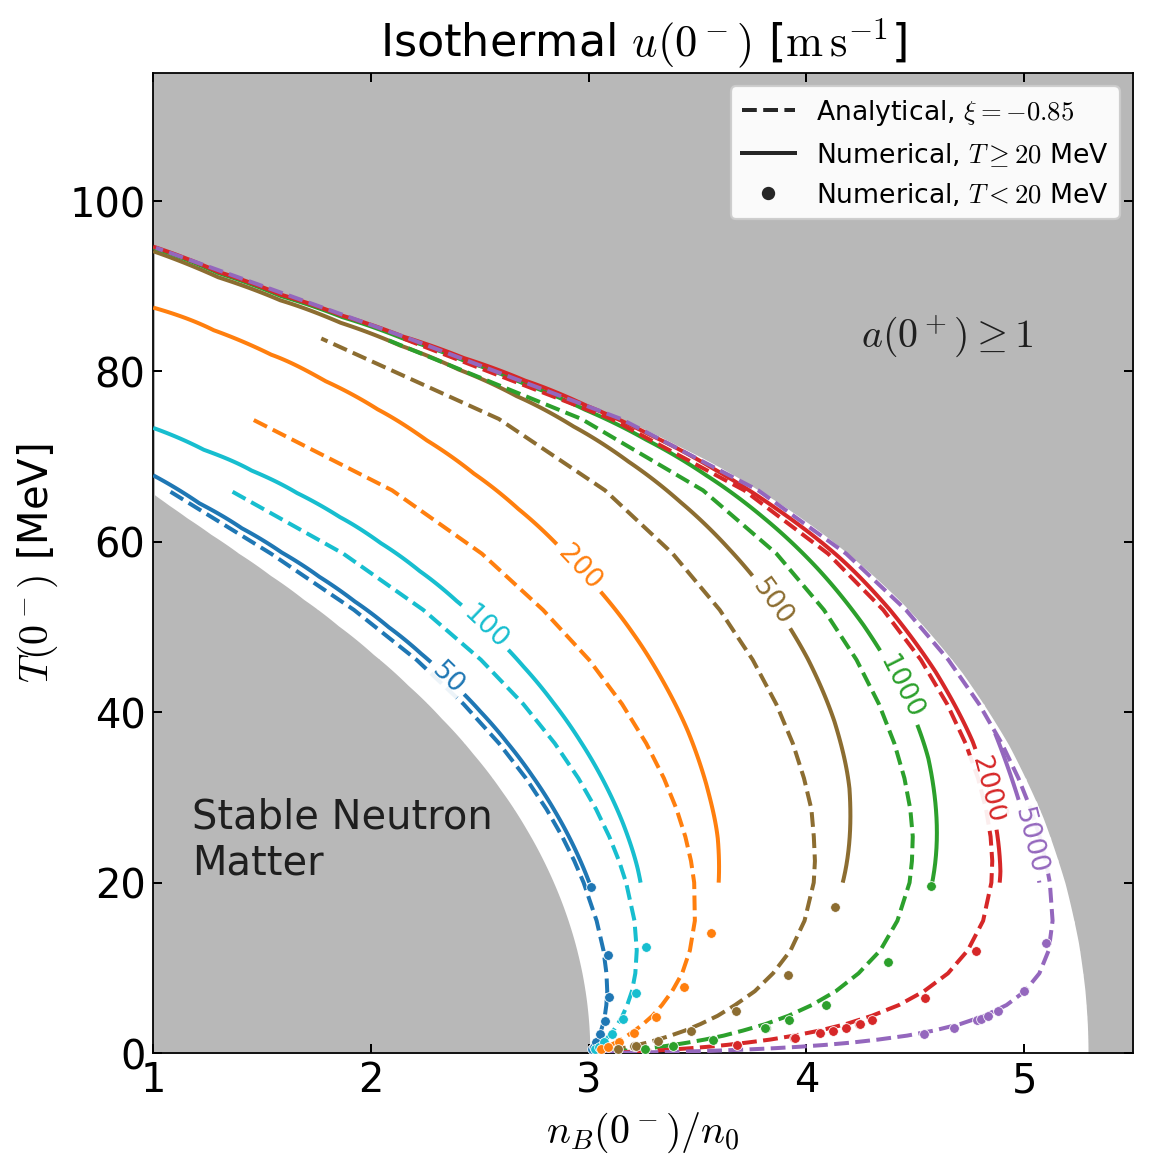

In [5]:
# Tunable plotting parameters
CONTOUR_LEVELS = (50., 100., 200., 500., 1000., 2000., 5000.)
CONTOUR_COLORS = ('#1f77b4', '#17becf', '#ff7f0e', '#8c6d31', '#2ca02c', '#d62728', '#9467bd')
FIGURE_SIZE = (7.2, 7.2)
FIGURE_DPI = 160
EXPORT_DPI = 220
CONSTRAINED_LAYOUT = True
BACKGROUND_COLOR = 'white'
FONT_FAMILY = 'DejaVu Sans'
MATH_FONT_SET = 'cm'
USE_TEX = False
BOX_ASPECT = 1.
X_LIMITS = (1., 5.5)
Y_LIMITS = (0., 115.)
X_SCALE = 'linear'
Y_SCALE = 'linear'
X_TICKS = (1., 2., 3., 4., 5.)
Y_TICKS = (0., 20., 40., 60., 80., 100.)
Y_TICK_LABELS = ('0', '20', '40', '60', '80', '100')
TITLE = r'Isothermal $u(0^-)$ [$\mathrm{m\,s^{-1}}$]'
TITLE_FONT_SIZE = 20
TITLE_PAD = 8
X_LABEL = r'$n_B(0^-)/n_0$'
Y_LABEL = r'$T(0^-)$ [MeV]'
AXIS_LABEL_FONT_SIZE = 18
TICK_LABEL_FONT_SIZE = 18
TICK_DIRECTION = 'in'
TICKS_TOP = True
TICKS_RIGHT = True
TICK_LENGTH = 4
TICK_WIDTH = .9
SPINE_LINE_WIDTH = .8
ANALYTICAL_LINE_STYLE = '--'
NUMERICAL_LINE_STYLE = '-'
LINE_WIDTH = 1.8
ANALYTICAL_ZORDER = 4
NUMERICAL_ZORDER = 3
NUMERICAL_SPLIT_TEMPERATURE = 20.
NUMERICAL_MARKER = 'o'
MARKER_SIZE = 19.
MARKER_EDGE_COLOR = 'white'
MARKER_EDGE_WIDTH = .35
MARKER_ALPHA = 1.
MARKER_ZORDER = 5
ISOLATED_ANALYTICAL_MARKER = 'x'
ISOLATED_ANALYTICAL_SIZE = 15.
LABEL_CURVES = True
CONTOUR_LABEL_FONT_SIZE = 12
CONTOUR_LABEL_FORMAT = '%g'
CONTOUR_LABEL_INLINE = True
CONTOUR_LABEL_INLINE_SPACING = 4
CONTOUR_LABEL_BACKGROUND_COLOR = 'white'
CONTOUR_LABEL_BACKGROUND_ALPHA = .92
CONTOUR_LABEL_BACKGROUND_PAD = .12
CONTOUR_LABEL_BACKGROUND_STYLE = 'round'
CONTOUR_LABEL_EDGE_COLOR = 'none'
CONTOUR_LABEL_ZORDER = 6
LABEL_TEMPERATURES = {50.: 44., 100.: 50., 200.: 57., 500.: 53., 1000.: 43., 2000.: 31., 5000.: 25.}
EXCLUDED_REGION_COLOR = '0.72'
EXCLUDED_REGION_ALPHA = 1.
EXCLUDED_REGION_ZORDER = 0
INNER_REGION_TEXT = 'Stable Neutron\nMatter'
INNER_REGION_POSITION = (1.18, 21.)
OUTER_REGION_TEXT = r'$a(0^+)\geq1$'
OUTER_REGION_POSITION = (4.25, 83.)
REGION_TEXT_COLOR = '0.12'
REGION_TEXT_FONT_SIZE = 18
REGION_TEXT_ZORDER = 6
LEGEND_LOCATION = 'upper right'
LEGEND_FONT_SIZE = 12
LEGEND_FRAME_ALPHA = .94
LEGEND_FACE_COLOR = 'white'
LEGEND_EDGE_COLOR = '0.8'
LEGEND_HANDLE_COLOR = '0.15'
LEGEND_MARKER_SIZE = 5.
LEGEND_LABELS = (rf"Analytical, $\xi={isothermal_analytic['identity']['physics']['xi']:g}$", r'Numerical, $T\geq20$ MeV', r'Numerical, $T<20$ MeV')
SHOW_SPEED_LEGEND = False
SPEED_LEGEND_LOCATION = 'lower right'
SPEED_LEGEND_TITLE = r'$u(0^-)$ [m s$^{-1}$]'
SPEED_LEGEND_FONT_SIZE = 11
SPEED_LEGEND_COLUMNS = 1
SPEED_LEGEND_ANCHOR = None
SPEED_LABELS = ('50', '100', '200', '500', '1000', '2000', '5000')
SHOW_GRID = False
EXPORT_STEM = 'isothermal-analytic-numerical-linearT'

from matplotlib.lines import Line2D
from matplotlib.contour import ContourSet

with plt.rc_context({'font.family': FONT_FAMILY, 'mathtext.fontset': MATH_FONT_SET,
                     'text.usetex': USE_TEX}):
    figure, axis = plt.subplots(figsize=FIGURE_SIZE, dpi=FIGURE_DPI,
                               constrained_layout=CONSTRAINED_LAYOUT, facecolor=BACKGROUND_COLOR)
    axis.set_facecolor(BACKGROUND_COLOR)
    for side, (temperatures, densities, edge) in saved_data.shading_boundaries(
            warm_data, isothermal_analytic, Y_LIMITS, X_LIMITS).items():
        shade = axis.fill_betweenx(temperatures, densities, edge, color=EXCLUDED_REGION_COLOR,
                                  alpha=EXCLUDED_REGION_ALPHA, zorder=EXCLUDED_REGION_ZORDER)
        shade.set_gid(f'excluded:{side}')
    warm_segments, label_positions = [], []
    for level, color in zip(CONTOUR_LEVELS, CONTOUR_COLORS):
        # Each run stops at an unresolved or out-of-window scheduled target.
        for segment in saved_data.analytical_segments(isothermal_analytic, level):
            if len(segment) >= 2:
                axis.plot(segment[:, 0], segment[:, 1], color=color,
                          linestyle=ANALYTICAL_LINE_STYLE, linewidth=LINE_WIDTH,
                          zorder=ANALYTICAL_ZORDER, gid=f'analytical:{level:g}')
            else:
                axis.scatter(segment[:, 0], segment[:, 1], color=color,
                             marker=ISOLATED_ANALYTICAL_MARKER, s=ISOLATED_ANALYTICAL_SIZE,
                             zorder=ANALYTICAL_ZORDER, gid=f'analytical-isolated:{level:g}')
        # Higher-speed levels have analytical results only, not numerical data.
        if level not in warm_data['levels_m_s']:
            continue
        index = list(warm_data['levels_m_s']).index(level)
        curve = saved_data.warm_curve(warm_data[f'curve_vertices_{index}'], NUMERICAL_SPLIT_TEMPERATURE)
        warm_segments.append([curve] if len(curve) >= 2 else [])
        if len(curve) >= 2:
            label_temperature = LABEL_TEMPERATURES[level]
            if curve[0, 1] <= label_temperature <= curve[-1, 1]:
                label_positions.append((np.interp(label_temperature, curve[:, 1], curve[:, 0]), label_temperature))
        dots = saved_data.cold_numerical_points(warm_data, numerical_logT, cold_endpoints,
                                               level, NUMERICAL_SPLIT_TEMPERATURE)
        if len(dots):
            axis.scatter(dots[:, 0], dots[:, 1], color=color, marker=NUMERICAL_MARKER,
                         s=MARKER_SIZE, edgecolors=MARKER_EDGE_COLOR, linewidths=MARKER_EDGE_WIDTH,
                         alpha=MARKER_ALPHA, zorder=MARKER_ZORDER, gid=f'numerical-cold:{level:g}')
    numerical_levels = [level for level in CONTOUR_LEVELS if level in warm_data['levels_m_s']]
    numerical_colors = [color for level, color in zip(CONTOUR_LEVELS, CONTOUR_COLORS) if level in numerical_levels]
    numerical_contours = ContourSet(axis, numerical_levels, warm_segments,
                                   colors=numerical_colors, linewidths=LINE_WIDTH,
                                   linestyles=NUMERICAL_LINE_STYLE, zorder=NUMERICAL_ZORDER)
    numerical_contours.set_gid('numerical-warm')
    axis.set(xlim=X_LIMITS, ylim=Y_LIMITS, xscale=X_SCALE, yscale=Y_SCALE)
    axis.set_xticks(X_TICKS)
    axis.set_yticks(Y_TICKS, labels=Y_TICK_LABELS)
    axis.set_box_aspect(BOX_ASPECT)
    if LABEL_CURVES:
        labels = axis.clabel(numerical_contours, inline=CONTOUR_LABEL_INLINE, fmt=CONTOUR_LABEL_FORMAT,
                             fontsize=CONTOUR_LABEL_FONT_SIZE, inline_spacing=CONTOUR_LABEL_INLINE_SPACING,
                             manual=label_positions)
        for label in labels:
            label.set_bbox(dict(facecolor=CONTOUR_LABEL_BACKGROUND_COLOR,
                                alpha=CONTOUR_LABEL_BACKGROUND_ALPHA, edgecolor=CONTOUR_LABEL_EDGE_COLOR,
                                boxstyle=f'{CONTOUR_LABEL_BACKGROUND_STYLE},pad={CONTOUR_LABEL_BACKGROUND_PAD}'))
            label.set_zorder(CONTOUR_LABEL_ZORDER)
    for position, text in ((INNER_REGION_POSITION, INNER_REGION_TEXT), (OUTER_REGION_POSITION, OUTER_REGION_TEXT)):
        axis.text(*position, text, color=REGION_TEXT_COLOR, fontsize=REGION_TEXT_FONT_SIZE, zorder=REGION_TEXT_ZORDER)
    axis.set_xlabel(X_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
    axis.set_ylabel(Y_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
    axis.set_title(TITLE, fontsize=TITLE_FONT_SIZE, pad=TITLE_PAD)
    axis.tick_params(direction=TICK_DIRECTION, top=TICKS_TOP, right=TICKS_RIGHT,
                     length=TICK_LENGTH, width=TICK_WIDTH, labelsize=TICK_LABEL_FONT_SIZE)
    for spine in axis.spines.values():
        spine.set_linewidth(SPINE_LINE_WIDTH)
    axis.grid(SHOW_GRID)
    method_handles = [
        Line2D([], [], color=LEGEND_HANDLE_COLOR, linestyle=ANALYTICAL_LINE_STYLE, linewidth=LINE_WIDTH, label=LEGEND_LABELS[0]),
        Line2D([], [], color=LEGEND_HANDLE_COLOR, linestyle=NUMERICAL_LINE_STYLE, linewidth=LINE_WIDTH, label=LEGEND_LABELS[1]),
        Line2D([], [], color=LEGEND_HANDLE_COLOR, linestyle='none', marker=NUMERICAL_MARKER,
               markersize=LEGEND_MARKER_SIZE, label=LEGEND_LABELS[2]),
    ]
    method_legend = axis.legend(handles=method_handles, loc=LEGEND_LOCATION, fontsize=LEGEND_FONT_SIZE,
                               framealpha=LEGEND_FRAME_ALPHA, facecolor=LEGEND_FACE_COLOR, edgecolor=LEGEND_EDGE_COLOR)
    if SHOW_SPEED_LEGEND:
        axis.add_artist(method_legend)
        speed_handles = [Line2D([], [], color=color, linestyle=ANALYTICAL_LINE_STYLE, linewidth=LINE_WIDTH,
                                label=label) for label, color in zip(SPEED_LABELS, CONTOUR_COLORS)]
        axis.legend(handles=speed_handles, loc=SPEED_LEGEND_LOCATION, title=SPEED_LEGEND_TITLE,
                    ncols=SPEED_LEGEND_COLUMNS, bbox_to_anchor=SPEED_LEGEND_ANCHOR,
                    fontsize=SPEED_LEGEND_FONT_SIZE, title_fontsize=SPEED_LEGEND_FONT_SIZE,
                    framealpha=LEGEND_FRAME_ALPHA, facecolor=LEGEND_FACE_COLOR, edgecolor=LEGEND_EDGE_COLOR)
    for extension in ('png', 'pdf'):
        path = OUTPUT_DIRECTORY / f'{EXPORT_STEM}.{extension}'
        figure.savefig(path, dpi=EXPORT_DPI, facecolor=BACKGROUND_COLOR)
        print('Saved', path.relative_to(ROOT))
    plt.show()


### Logarithmic-temperature view

Adds separately calculated analytical levels at 10,000, 20,000, 50,000, 100,000, 200,000, 500,000 and 1,000,000 m/s. Existing numerical curves and cold dots are preserved. New high-speed cold numerical dots are computed separately below; no high-speed warm numerical curves are inferred. Only consecutive validated analytical targets are connected. Legend suffixes: k = 1,000 and M = 1,000,000; units remain m/s.

The next cell preserves the six full-numerical roots near 0.01, 0.03 and 0.1 MeV at 500 and 2000 m/s, and adds a separate batch targeting 10,000, 50,000 and 500,000 m/s at 0.01 and 0.02755 MeV. Levels with no accepted root receive one fallback target at 0.09779 MeV. It checkpoints every evaluation and resumes; set both `CALCULATE_COLD_NUMERICAL = False` and `CALCULATE_HIGH_COLD_NUMERICAL = False` for saved-data-only loading. Temperatures should come from the analytical schedule so physical boundaries are directly solved. Analytical densities seed the search only. Nearby profiles may seed the BVP; otherwise it uses the layer-resolved initializer. Each dot requires numerical speed agreement within 0.5% plus BVP, composition, EOS and flux checks. Timeouts remain missing points. The plotting cell itself makes no solver calls.

Saved local run: all six standard-tolerance roots converged (largest speed error 0.315%); these six roots increased the cold numerical count from 58 to 64. One stricter mesh/tail check at 0.01 MeV timed out, so mesh/tail independence of the new points has not been demonstrated. The 2000 m/s root at 0.01 MeV retains one quadrature roundoff warning despite passing the stated residual checks. Full diagnostics are saved alongside the points.

High-speed batch result: one accepted 10,000 m/s dot at T = 0.027550997842357025 MeV and nB(0-)/n0 = 3.2359548050553277; computed speed = 10003.19563277806 m/s (0.03196% target error). Both primary and warmer fallback attempts for 50,000 and 500,000 m/s timed out at 90 seconds, as did the 0.01-MeV 10,000 m/s attempt. These seven unresolved targets are not plotted. There are now 65 numerical cold dots, not completed coverage at all three requested high speeds. Eight targets used ten new BVP evaluations (three converged density trials and seven timeouts). All diagnostics are checkpointed separately; completed or exhausted work is reused on rerun. No new tighter mesh/tail check was performed for the high-speed dot.


In [2]:
# Full numerical cold-point calculation controls (no plotting)
CALCULATE_COLD_NUMERICAL = True
COLD_TEMPERATURES = (0.01, 0.027550997842357025, 0.09779327685429287)
COLD_LEVELS = (500., 2000.)
COLD_WORKERS = 2
COLD_TRIAL_TIMEOUT_SECONDS = 90.
COLD_TARGET_TIMEOUT_SECONDS = 300.
COLD_MAX_EVALUATIONS_PER_TARGET = 4
COLD_INITIAL_NODES = 300
COLD_MAX_NODES = 12000
COLD_BVP_TOLERANCE = 1.e-4
COLD_TAIL_EPSILON = 1.e-3
COLD_OUTPUT_NAME = 'isothermal-cold-numerical-points.npy'
# Independent batch: preserve the completed lower-speed checkpoint.
CALCULATE_HIGH_COLD_NUMERICAL = True
HIGH_COLD_TEMPERATURES = (0.01, 0.027550997842357025)
HIGH_COLD_LEVELS = (10000., 50000., 500000.)
HIGH_COLD_OUTPUT_NAME = 'isothermal-cold-numerical-high-speed.npy'
HIGH_COLD_FALLBACK_TEMPERATURES = (0.09779327685429287,)
HIGH_COLD_FALLBACK_OUTPUT_NAME = 'isothermal-cold-numerical-high-speed-fallback.npy'

from pathlib import Path
from collections import Counter
import sys
import importlib
import numpy as np

ROOT = Path.cwd()
HELPER_DIRECTORY = ROOT / 'new_paper_calculations/26-10-02'
if str(HELPER_DIRECTORY) not in sys.path:
    sys.path.insert(0, str(HELPER_DIRECTORY))
import notebook_isothermal
import notebook_isothermal_cold
notebook_isothermal_cold = importlib.reload(notebook_isothermal_cold)
COLD_OUTPUT_PATH = ROOT / 'local_analysis_results/26-10-02' / COLD_OUTPUT_NAME
# An existing analytical result supplies density guesses only; no analytical rerun.
if 'isothermal_analytic' not in globals():
    isothermal_analytic = notebook_isothermal.load_reference(ROOT)
cold_inputs = notebook_isothermal_cold.load_inputs(
    isothermal_analytic, temperatures=COLD_TEMPERATURES, levels=COLD_LEVELS)
if CALCULATE_COLD_NUMERICAL:
    cold_numerical_extra = notebook_isothermal_cold.calculate(
        cold_inputs, COLD_OUTPUT_PATH, temperatures=COLD_TEMPERATURES, levels=COLD_LEVELS,
        workers=COLD_WORKERS, trial_timeout=COLD_TRIAL_TIMEOUT_SECONDS,
        target_timeout=COLD_TARGET_TIMEOUT_SECONDS, max_evaluations=COLD_MAX_EVALUATIONS_PER_TARGET,
        n_mesh=COLD_INITIAL_NODES, max_nodes=COLD_MAX_NODES,
        tol_bvp=COLD_BVP_TOLERANCE, tail_eps=COLD_TAIL_EPSILON)
elif COLD_OUTPUT_PATH.exists():
    cold_numerical_extra = np.load(COLD_OUTPUT_PATH, allow_pickle=True).item()
else:
    cold_numerical_extra = {'targets': {}}
print('New numerical targets:', dict(Counter(r['status'] for r in cold_numerical_extra['targets'].values())))
print('Saved', COLD_OUTPUT_PATH)
print('Only accepted numerical roots become dots; failed attempts remain unplotted.')

HIGH_COLD_OUTPUT_PATH = ROOT / 'local_analysis_results/26-10-02' / HIGH_COLD_OUTPUT_NAME
high_cold_inputs = notebook_isothermal_cold.load_inputs(
    isothermal_analytic, temperatures=HIGH_COLD_TEMPERATURES, levels=HIGH_COLD_LEVELS)
if CALCULATE_HIGH_COLD_NUMERICAL:
    cold_numerical_high = notebook_isothermal_cold.calculate(
        high_cold_inputs, HIGH_COLD_OUTPUT_PATH,
        temperatures=HIGH_COLD_TEMPERATURES, levels=HIGH_COLD_LEVELS,
        workers=COLD_WORKERS, trial_timeout=COLD_TRIAL_TIMEOUT_SECONDS,
        target_timeout=COLD_TARGET_TIMEOUT_SECONDS, max_evaluations=COLD_MAX_EVALUATIONS_PER_TARGET,
        n_mesh=COLD_INITIAL_NODES, max_nodes=COLD_MAX_NODES,
        tol_bvp=COLD_BVP_TOLERANCE, tail_eps=COLD_TAIL_EPSILON)
elif HIGH_COLD_OUTPUT_PATH.exists():
    cold_numerical_high = np.load(HIGH_COLD_OUTPUT_PATH, allow_pickle=True).item()
else:
    cold_numerical_high = {'targets': {}}
print('High-speed numerical targets:', dict(Counter(r['status'] for r in cold_numerical_high['targets'].values())))
print('Saved', HIGH_COLD_OUTPUT_PATH)

# One warmer cold target only for levels with no accepted point in the first batch.
# A spent unsuccessful target is not retried; it remains explicit in its checkpoint.
HIGH_COLD_FALLBACK_PATH = ROOT / 'local_analysis_results/26-10-02' / HIGH_COLD_FALLBACK_OUTPUT_NAME
fallback_levels = tuple(level for level in HIGH_COLD_LEVELS
                       if not len(notebook_isothermal_cold.new_points(cold_numerical_high, level)))
if CALCULATE_HIGH_COLD_NUMERICAL and cold_numerical_high.get('work_complete') and fallback_levels:
    fallback_inputs = notebook_isothermal_cold.load_inputs(
        isothermal_analytic, temperatures=HIGH_COLD_FALLBACK_TEMPERATURES, levels=fallback_levels)
    cold_numerical_high_fallback = notebook_isothermal_cold.calculate(
        fallback_inputs, HIGH_COLD_FALLBACK_PATH,
        temperatures=HIGH_COLD_FALLBACK_TEMPERATURES, levels=fallback_levels,
        workers=COLD_WORKERS, trial_timeout=COLD_TRIAL_TIMEOUT_SECONDS,
        target_timeout=COLD_TARGET_TIMEOUT_SECONDS, max_evaluations=COLD_MAX_EVALUATIONS_PER_TARGET,
        n_mesh=COLD_INITIAL_NODES, max_nodes=COLD_MAX_NODES,
        tol_bvp=COLD_BVP_TOLERANCE, tail_eps=COLD_TAIL_EPSILON)
elif HIGH_COLD_FALLBACK_PATH.exists():
    cold_numerical_high_fallback = np.load(HIGH_COLD_FALLBACK_PATH, allow_pickle=True).item()
else:
    cold_numerical_high_fallback = {'targets': {}}
print('Warmer fallback targets:', dict(Counter(r['status'] for r in cold_numerical_high_fallback['targets'].values())))
print('Saved', HIGH_COLD_FALLBACK_PATH)


/Users/janshao/NSM_related/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Cold numerical targets:   0%|                                                       | 0/6 [00:00<?, ?target/s]

Saved numerical evaluations: 0point [00:00, ?point/s]

Cold numerical targets: 100%|████████████████████████████████████████████| 6/6 [00:00<00:00, 10050.25target/s]

Saved numerical evaluations: 13point [00:00, 74387.38point/s]

...

Cold numerical targets: 100%|█████████████████████████████████████████████| 2/2 [00:00<00:00, 3154.80target/s]

Saved numerical evaluations: 2point [00:00, 13148.29point/s]

Saved numerical evaluations: 2point [00:00, 2563.76point/s] 


Cold numerical targets: 100%|█████████████████████████████████████████████| 2/2 [00:00<00:00, 1326.26target/s]

Warmer fallback targets: {'unresolved': 2}
Saved /Users/janshao/NSM_related/local_analysis_results/26-10-02/isothermal-cold-numerical-high-speed-fallback.npy


Saved local_analysis_results/26-10-02/isothermal-analytic-numerical-logT.png
Saved local_analysis_results/26-10-02/isothermal-analytic-numerical-logT.pdf


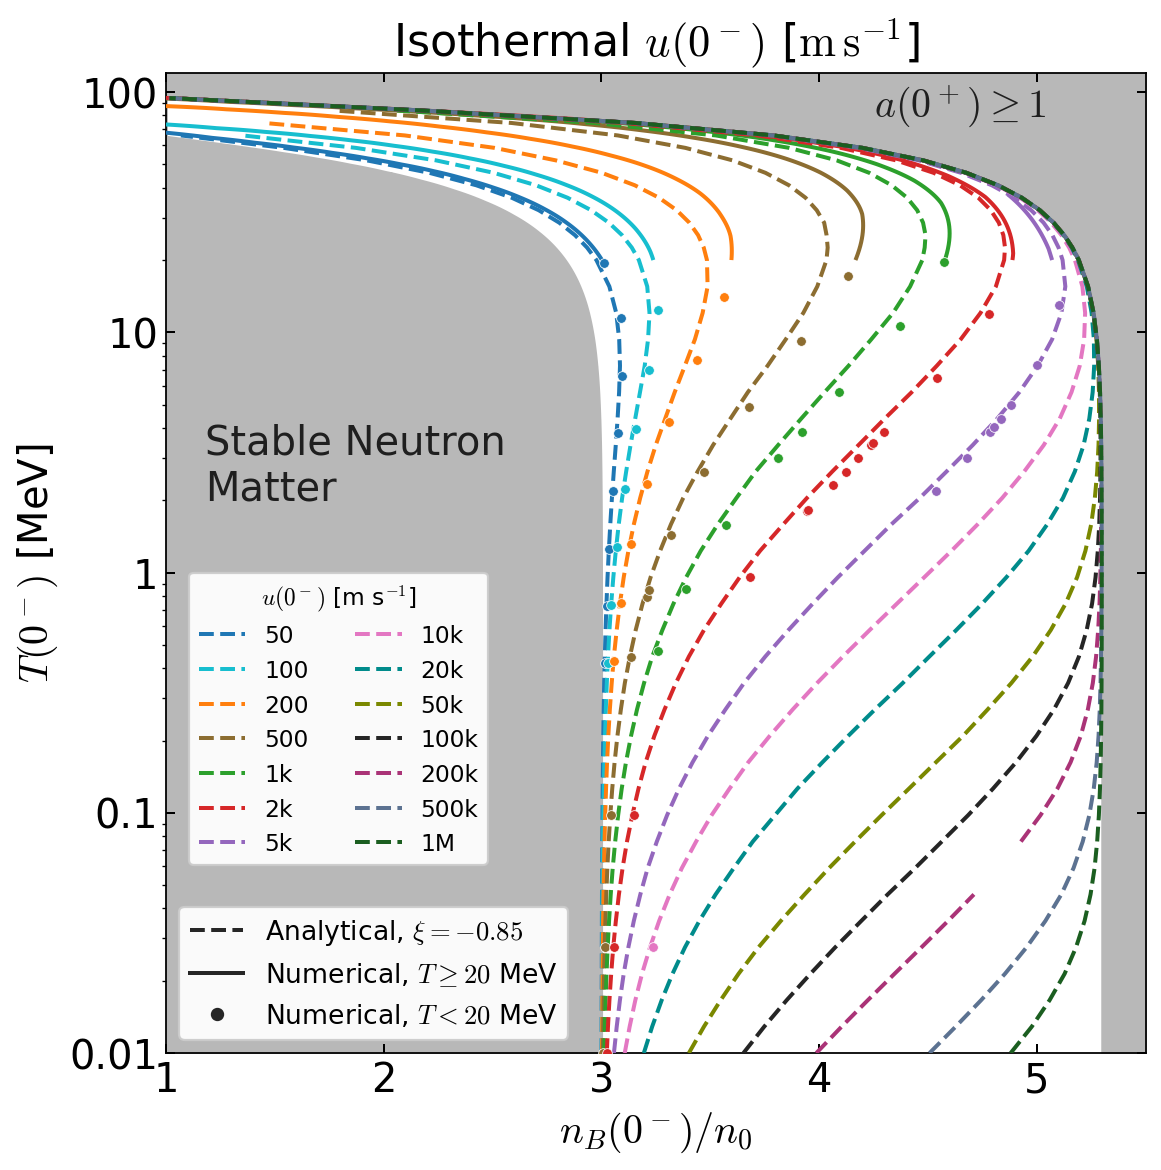

In [3]:
# Tunable plotting parameters
CONTOUR_LEVELS = (50., 100., 200., 500., 1000., 2000., 5000., 10000., 20000., 50000., 100000., 200000., 500000., 1000000.)
CONTOUR_COLORS = ('#1f77b4', '#17becf', '#ff7f0e', '#8c6d31', '#2ca02c', '#d62728', '#9467bd', '#e377c2', '#008b8b', '#7a8800', '#252525', '#aa3377', '#5c7291', '#1b5e20')
FIGURE_SIZE = (7.2, 7.2)
FIGURE_DPI = 160
EXPORT_DPI = 220
CONSTRAINED_LAYOUT = True
BACKGROUND_COLOR = 'white'
FONT_FAMILY = 'DejaVu Sans'
MATH_FONT_SET = 'cm'
USE_TEX = False
BOX_ASPECT = 1.
X_LIMITS = (1., 5.5)
Y_LIMITS = (.01, 120.)
X_SCALE = 'linear'
Y_SCALE = 'log'
X_TICKS = (1., 2., 3., 4., 5.)
Y_TICKS = (.01, .1, 1., 10., 100.)
Y_TICK_LABELS = ('0.01', '0.1', '1', '10', '100')
TITLE = r'Isothermal $u(0^-)$ [$\mathrm{m\,s^{-1}}$]'
TITLE_FONT_SIZE = 20
TITLE_PAD = 8
X_LABEL = r'$n_B(0^-)/n_0$'
Y_LABEL = r'$T(0^-)$ [MeV]'
AXIS_LABEL_FONT_SIZE = 18
TICK_LABEL_FONT_SIZE = 18
TICK_DIRECTION = 'in'
TICKS_TOP = True
TICKS_RIGHT = True
TICK_LENGTH = 4
TICK_WIDTH = .9
SPINE_LINE_WIDTH = .8
ANALYTICAL_LINE_STYLE = '--'
NUMERICAL_LINE_STYLE = '-'
LINE_WIDTH = 1.8
ANALYTICAL_ZORDER = 4
NUMERICAL_ZORDER = 3
NUMERICAL_SPLIT_TEMPERATURE = 20.
NUMERICAL_MARKER = 'o'
MARKER_SIZE = 19.
MARKER_EDGE_COLOR = 'white'
MARKER_EDGE_WIDTH = .35
MARKER_ALPHA = 1.
MARKER_ZORDER = 5
ISOLATED_ANALYTICAL_MARKER = 'x'
ISOLATED_ANALYTICAL_SIZE = 15.
LABEL_CURVES = False
CONTOUR_LABEL_FONT_SIZE = 12
CONTOUR_LABEL_FORMAT = '%g'
CONTOUR_LABEL_INLINE = True
CONTOUR_LABEL_INLINE_SPACING = 4
CONTOUR_LABEL_BACKGROUND_COLOR = 'white'
CONTOUR_LABEL_BACKGROUND_ALPHA = .92
CONTOUR_LABEL_BACKGROUND_PAD = .12
CONTOUR_LABEL_BACKGROUND_STYLE = 'round'
CONTOUR_LABEL_EDGE_COLOR = 'none'
CONTOUR_LABEL_ZORDER = 6
LABEL_TEMPERATURES = {50.: 44., 100.: 50., 200.: 57., 500.: 53., 1000.: 43., 2000.: 31., 5000.: 25.}
EXCLUDED_REGION_COLOR = '0.72'
EXCLUDED_REGION_ALPHA = 1.
EXCLUDED_REGION_ZORDER = 0
INNER_REGION_TEXT = 'Stable Neutron\nMatter'
INNER_REGION_POSITION = (1.18, 2.)
OUTER_REGION_TEXT = r'$a(0^+)\geq1$'
OUTER_REGION_POSITION = (4.25, 80.)
REGION_TEXT_COLOR = '0.12'
REGION_TEXT_FONT_SIZE = 18
REGION_TEXT_ZORDER = 6
LEGEND_LOCATION = 'lower left'
LEGEND_FONT_SIZE = 12
LEGEND_FRAME_ALPHA = .94
LEGEND_FACE_COLOR = 'white'
LEGEND_EDGE_COLOR = '0.8'
LEGEND_HANDLE_COLOR = '0.15'
LEGEND_MARKER_SIZE = 5.
LEGEND_LABELS = (rf"Analytical, $\xi={isothermal_analytic['identity']['physics']['xi']:g}$", r'Numerical, $T\geq20$ MeV', r'Numerical, $T<20$ MeV')
SHOW_SPEED_LEGEND = True
SPEED_LEGEND_LOCATION = 'lower left'
SPEED_LEGEND_TITLE = r'$u(0^-)$ [m s$^{-1}$]'
SPEED_LEGEND_FONT_SIZE = 10.5
SPEED_LEGEND_COLUMNS = 2
SPEED_LEGEND_ANCHOR = (.012, .18)
SPEED_LABELS = ('50', '100', '200', '500', '1k', '2k', '5k', '10k', '20k', '50k', '100k', '200k', '500k', '1M')
SHOW_GRID = False
EXPORT_STEM = 'isothermal-analytic-numerical-logT'

from matplotlib.lines import Line2D
from matplotlib.contour import ContourSet

with plt.rc_context({'font.family': FONT_FAMILY, 'mathtext.fontset': MATH_FONT_SET,
                     'text.usetex': USE_TEX}):
    figure, axis = plt.subplots(figsize=FIGURE_SIZE, dpi=FIGURE_DPI,
                               constrained_layout=CONSTRAINED_LAYOUT, facecolor=BACKGROUND_COLOR)
    axis.set_facecolor(BACKGROUND_COLOR)
    for side, (temperatures, densities, edge) in saved_data.shading_boundaries(
            warm_data, isothermal_analytic, Y_LIMITS, X_LIMITS).items():
        shade = axis.fill_betweenx(temperatures, densities, edge, color=EXCLUDED_REGION_COLOR,
                                  alpha=EXCLUDED_REGION_ALPHA, zorder=EXCLUDED_REGION_ZORDER)
        shade.set_gid(f'excluded:{side}')
    warm_segments, label_positions = [], []
    for level, color in zip(CONTOUR_LEVELS, CONTOUR_COLORS):
        # Each run stops at an unresolved or out-of-window scheduled target.
        for segment in saved_data.analytical_segments(isothermal_analytic, level):
            if len(segment) >= 2:
                axis.plot(segment[:, 0], segment[:, 1], color=color,
                          linestyle=ANALYTICAL_LINE_STYLE, linewidth=LINE_WIDTH,
                          zorder=ANALYTICAL_ZORDER, gid=f'analytical:{level:g}')
            else:
                axis.scatter(segment[:, 0], segment[:, 1], color=color,
                             marker=ISOLATED_ANALYTICAL_MARKER, s=ISOLATED_ANALYTICAL_SIZE,
                             zorder=ANALYTICAL_ZORDER, gid=f'analytical-isolated:{level:g}')
        dots = saved_data.cold_numerical_points(warm_data, numerical_logT, cold_endpoints,
                                               level, NUMERICAL_SPLIT_TEMPERATURE)
        # Additional roots come only from the full numerical computation cell.
        for payload_name in ('cold_numerical_extra', 'cold_numerical_high', 'cold_numerical_high_fallback'):
            if payload_name in globals():
                extra_dots = notebook_isothermal_cold.new_points(globals()[payload_name], level)
                dots = np.unique(np.vstack((dots, extra_dots)), axis=0)
        if len(dots):
            axis.scatter(dots[:, 0], dots[:, 1], color=color, marker=NUMERICAL_MARKER,
                         s=MARKER_SIZE, edgecolors=MARKER_EDGE_COLOR, linewidths=MARKER_EDGE_WIDTH,
                         alpha=MARKER_ALPHA, zorder=MARKER_ZORDER, gid=f'numerical-cold:{level:g}')
        # Warm numerical curves exist only at the archived levels.
        if level not in warm_data['levels_m_s']:
            continue
        index = list(warm_data['levels_m_s']).index(level)
        curve = saved_data.warm_curve(warm_data[f'curve_vertices_{index}'], NUMERICAL_SPLIT_TEMPERATURE)
        warm_segments.append([curve] if len(curve) >= 2 else [])
        if len(curve) >= 2:
            label_temperature = LABEL_TEMPERATURES[level]
            if curve[0, 1] <= label_temperature <= curve[-1, 1]:
                label_positions.append((np.interp(label_temperature, curve[:, 1], curve[:, 0]), label_temperature))
    numerical_levels = [level for level in CONTOUR_LEVELS if level in warm_data['levels_m_s']]
    numerical_colors = [color for level, color in zip(CONTOUR_LEVELS, CONTOUR_COLORS) if level in numerical_levels]
    numerical_contours = ContourSet(axis, numerical_levels, warm_segments,
                                   colors=numerical_colors, linewidths=LINE_WIDTH,
                                   linestyles=NUMERICAL_LINE_STYLE, zorder=NUMERICAL_ZORDER)
    numerical_contours.set_gid('numerical-warm')
    axis.set(xlim=X_LIMITS, ylim=Y_LIMITS, xscale=X_SCALE, yscale=Y_SCALE)
    axis.set_xticks(X_TICKS)
    axis.set_yticks(Y_TICKS, labels=Y_TICK_LABELS)
    axis.set_box_aspect(BOX_ASPECT)
    if LABEL_CURVES:
        labels = axis.clabel(numerical_contours, inline=CONTOUR_LABEL_INLINE, fmt=CONTOUR_LABEL_FORMAT,
                             fontsize=CONTOUR_LABEL_FONT_SIZE, inline_spacing=CONTOUR_LABEL_INLINE_SPACING,
                             manual=label_positions)
        for label in labels:
            label.set_bbox(dict(facecolor=CONTOUR_LABEL_BACKGROUND_COLOR,
                                alpha=CONTOUR_LABEL_BACKGROUND_ALPHA, edgecolor=CONTOUR_LABEL_EDGE_COLOR,
                                boxstyle=f'{CONTOUR_LABEL_BACKGROUND_STYLE},pad={CONTOUR_LABEL_BACKGROUND_PAD}'))
            label.set_zorder(CONTOUR_LABEL_ZORDER)
    for position, text in ((INNER_REGION_POSITION, INNER_REGION_TEXT), (OUTER_REGION_POSITION, OUTER_REGION_TEXT)):
        axis.text(*position, text, color=REGION_TEXT_COLOR, fontsize=REGION_TEXT_FONT_SIZE, zorder=REGION_TEXT_ZORDER)
    axis.set_xlabel(X_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
    axis.set_ylabel(Y_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
    axis.set_title(TITLE, fontsize=TITLE_FONT_SIZE, pad=TITLE_PAD)
    axis.tick_params(direction=TICK_DIRECTION, top=TICKS_TOP, right=TICKS_RIGHT,
                     length=TICK_LENGTH, width=TICK_WIDTH, labelsize=TICK_LABEL_FONT_SIZE)
    for spine in axis.spines.values():
        spine.set_linewidth(SPINE_LINE_WIDTH)
    axis.grid(SHOW_GRID)
    method_handles = [
        Line2D([], [], color=LEGEND_HANDLE_COLOR, linestyle=ANALYTICAL_LINE_STYLE, linewidth=LINE_WIDTH, label=LEGEND_LABELS[0]),
        Line2D([], [], color=LEGEND_HANDLE_COLOR, linestyle=NUMERICAL_LINE_STYLE, linewidth=LINE_WIDTH, label=LEGEND_LABELS[1]),
        Line2D([], [], color=LEGEND_HANDLE_COLOR, linestyle='none', marker=NUMERICAL_MARKER,
               markersize=LEGEND_MARKER_SIZE, label=LEGEND_LABELS[2]),
    ]
    method_legend = axis.legend(handles=method_handles, loc=LEGEND_LOCATION, fontsize=LEGEND_FONT_SIZE,
                               framealpha=LEGEND_FRAME_ALPHA, facecolor=LEGEND_FACE_COLOR, edgecolor=LEGEND_EDGE_COLOR)
    if SHOW_SPEED_LEGEND:
        axis.add_artist(method_legend)
        speed_handles = [Line2D([], [], color=color, linestyle=ANALYTICAL_LINE_STYLE, linewidth=LINE_WIDTH,
                                label=label) for label, color in zip(SPEED_LABELS, CONTOUR_COLORS)]
        axis.legend(handles=speed_handles, loc=SPEED_LEGEND_LOCATION, title=SPEED_LEGEND_TITLE,
                    ncols=SPEED_LEGEND_COLUMNS, bbox_to_anchor=SPEED_LEGEND_ANCHOR,
                    fontsize=SPEED_LEGEND_FONT_SIZE, title_fontsize=SPEED_LEGEND_FONT_SIZE,
                    framealpha=LEGEND_FRAME_ALPHA, facecolor=LEGEND_FACE_COLOR, edgecolor=LEGEND_EDGE_COLOR)
    for extension in ('png', 'pdf'):
        path = OUTPUT_DIRECTORY / f'{EXPORT_STEM}.{extension}'
        figure.savefig(path, dpi=EXPORT_DPI, facecolor=BACKGROUND_COLOR)
        print('Saved', path.relative_to(ROOT))
    plt.show()
